# Modelo VAEP Atômico Enriquecido com Features de Tracking

Este notebook implementa e avalia um modelo de valoração de ações no futebol (VAEP - Valuing Actions by Estimating Probabilities) com uma abordagem híbrida, combinando dados de evento (SPADL) com features extraídas de dados de tracking.

## Fluxo de Trabalho Experimental

O processo é dividido em **três grandes etapas** para permitir uma comparação justa e clara do impacto das features de tracking:

### 1. Modelo VAEP Baseline
- **Objetivo:** Estabelecer uma linha de base de performance.
- **Metodologia:** Um modelo VAEP atômico padrão é treinado utilizando exclusivamente features derivadas dos dados de evento SPADL. Este modelo serve como nosso ponto de referência.

### 2. Classificador de Sucesso Enriquecido
- **Objetivo:** Prever a probabilidade de uma ação ser bem-sucedida, utilizando um contexto tático que não está presente nos dados de evento.
- **Metodologia:**
    - Extraímos a feature **`compactação defensiva`** dos dados de tracking para cada ação.
    - Um classificador (XGBoost) é treinado para prever o sucesso de uma ação (`result_name`). As suas features de entrada são as features SPADL padrão **MAIS** a feature de `compactação defensiva`.
    - A performance deste classificador é avaliada para garantir que ele aprendeu padrões significativos.

### 3. Modelo VAEP Final (Híbrido)
- **Objetivo:** Avaliar o impacto de um classificador de sucesso "mais inteligente" na performance final do VAEP.
- **Metodologia:**
    - O classificador treinado na Etapa 2 é usado para gerar uma nova feature: `success_score` (a probabilidade de sucesso da ação).
    - Um novo modelo VAEP é treinado. Suas features de entrada são as features SPADL padrão **MAIS** a feature `success_score`.
    - A performance deste modelo final é comparada com o VAEP Baseline para quantificar o ganho obtido ao incorporar o contexto dos dados de tracking de forma indireta (através do classificador).

Ao final, o notebook gera os valores de VAEP para os jogadores e plota gráficos de diagnóstico detalhados para os modelos finais.

In [1]:
import pandas as pd
import numpy as np
from tqdm import tqdm
from xgboost import XGBClassifier
from sklearn.metrics import brier_score_loss
from socceraction.vaep import features as ft
from socceraction.vaep import labels as lab
from socceraction.vaep import formula as fm
from socceraction.atomic.spadl import convert_to_atomic
from sklearn.model_selection import GroupShuffleSplit, train_test_split
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve, roc_auc_score
import seaborn as sns
import os

In [2]:
import warnings
warnings.filterwarnings('ignore')

---

## Carregando dados de Evento e Transformação para Atomic SPADL

In [3]:
df_spadl = pd.read_parquet('spadl_events/spadl_ltr.parquet')
df_spadl.head()

,game_id,period_id,team_id,player_id,start_x,start_y,end_x,end_y,original_event_id,time_seconds,type_id,type_name,result_id,result_name,bodypart_id,bodypart_name,action_id
0,13335,1,5.0,15620,0.503105,0.504544,0.326924,0.436265,12926009.0,153.887,0,pass,1,success,5,foot_right,0
1,13335,1,5.0,4696,0.329743,0.457456,0.760200,0.735603,12926647.0,156.623,0,pass,0,fail,5,foot_right,1
2,13335,1,5.0,14278,0.760200,0.735603,NaN,NaN,12926642.0,159.860,9,tackle,0,fail,0,foot,2
3,13335,1,11.0,284,0.239800,0.264397,NaN,NaN,12926642.0,159.860,9,tackle,1,success,0,foot,3
4,13335,1,5.0,13068,0.760200,0.735603,NaN,NaN,12926642.0,159.860,9,tackle,0,fail,0,foot,4


In [4]:
## Mantendo apenas a primeira linha de cada event_id

df_spadl = df_spadl.sort_values(by='time_seconds').drop_duplicates(subset=['original_event_id'], keep = 'first')

df_spadl['result_name'] = df_spadl['result_id'].map({
    1: 'success',
    0: 'fail'
})

In [5]:
# Ordenar ações por tempo dentro de cada jogo
df_spadl = df_spadl.sort_values(by=['game_id', 'period_id', 'time_seconds', 'action_id']).reset_index(drop=True)

## Conversão de SPADL para Atomic SPADL

In [6]:
df_atomic = convert_to_atomic(df_spadl)
df_atomic.head()

,game_id,original_event_id,action_id,period_id,time_seconds,team_id,player_id,x,y,dx,dy,type_id,bodypart_id
0,13335,12926009.0,0,1,153.887,5.0,15620,0.503105,0.504544,-0.176181,-0.068279,0,5
1,13335,12926009.0,1,1,155.255,5.0,4696,0.326924,0.436265,0.000000,0.000000,23,0
2,13335,12926647.0,2,1,156.623,5.0,4696,0.329743,0.457456,0.430457,0.278147,0,5
3,13335,12926642.0,3,1,159.860,5.0,14278,0.760200,0.735603,NaN,NaN,9,0
4,13335,20246849.0,4,1,159.893,11.0,284,0.239800,0.264397,0.179133,-0.151000,18,0


Adicionar a coluna `type_name` ao Atomic SPADL:

In [7]:
from socceraction.atomic.spadl.config import actiontypes as atomic_actiontypes

# Garante que o df_atomic.type_id só tenha valores válidos
max_atomic_id = len(atomic_actiontypes) - 1

df_atomic['type_name'] = df_atomic['type_id'].apply(
    lambda x: atomic_actiontypes[x] if 0 <= x <= max_atomic_id
              else f"unknown_{x}"
)

---

## Preparar dados para o Classificador de Sucesso

Carrega as features de tracking e prepara os dados para o classificador de sucesso:

In [8]:
print("Iniciando a integração das features de tracking...")
pasta_features_compaction = 'tracking_features/compaction/parquets_compaction'
lista_dfs_features = []
arquivos_features = [f for f in os.listdir(pasta_features_compaction) if f.endswith('.parquet')]

for nome_arquivo in tqdm(arquivos_features, desc="Carregando features de compactação"):
    caminho = os.path.join(pasta_features_compaction, nome_arquivo)
    lista_dfs_features.append(pd.read_parquet(caminho))

df_compaction_total = pd.concat(lista_dfs_features, ignore_index=True)
df_compaction_total.rename(columns={'possession_id': 'original_event_id'}, inplace=True)

# Garante que os tipos das chaves de merge são os mesmos para um merge seguro
df_compaction_total['original_event_id'] = df_compaction_total['original_event_id'].astype(float).astype(int).astype(str)
df_compaction_total['game_id'] = df_compaction_total['game_id'].astype(int)

print("\nFeatures de tracking carregadas e prontas.")
display(df_compaction_total.head())

Iniciando a integração das features de tracking...


Carregando features de compactação: 100%|██████████| 233/233 [00:03<00:00, 63.48it/s]


Features de tracking carregadas e prontas.


,original_event_id,defensive_compaction_x,defensive_compaction_y,game_id
0,12926009,11.509149,14.339360,13335
1,12926010,10.685111,11.034581,13335
2,12926642,17.266214,10.825132,13335
3,12926643,17.266214,10.825132,13335
4,12926647,13.028324,14.413517,13335


Adiciona coluna `result_name` ao Atomic SPADL:


In [9]:
df_atomic['original_event_id'] = df_atomic['original_event_id'].astype(str)
events_results = df_spadl.sort_values(by='time_seconds')[['original_event_id', 'result_name']].drop_duplicates(subset=['original_event_id'])
events_results['original_event_id'] = events_results['original_event_id'].astype(str)
df_atomic = df_atomic.merge(events_results, on='original_event_id', how='left')

df_atomic.head()

,game_id,original_event_id,action_id,period_id,time_seconds,team_id,player_id,x,y,dx,dy,type_id,bodypart_id,type_name,result_name
0,13335,12926009.0,0,1,153.887,5.0,15620,0.503105,0.504544,-0.176181,-0.068279,0,5,pass,success
1,13335,12926009.0,1,1,155.255,5.0,4696,0.326924,0.436265,0.000000,0.000000,23,0,receival,success
2,13335,12926647.0,2,1,156.623,5.0,4696,0.329743,0.457456,0.430457,0.278147,0,5,pass,fail
3,13335,12926642.0,3,1,159.860,5.0,14278,0.760200,0.735603,NaN,NaN,9,0,tackle,fail
4,13335,20246849.0,4,1,159.893,11.0,284,0.239800,0.264397,0.179133,-0.151000,18,0,clearance,success


---

# Features e Labels para o Classificador de Sucesso

In [10]:
import socceraction.atomic.spadl as atomicspadl
import socceraction.atomic.vaep.features as fs
import socceraction.atomic.vaep.labels as lab
import socceraction.atomic.vaep.formula as fm

### Features

In [11]:
# ==========================
# 2. FEATURES ATOMIC
# ==========================

xfns = [
    fs.actiontype_onehot, fs.bodypart_onehot,
    fs.goalscore, fs.location, fs.polar,
    fs.direction, fs.team, fs.time, fs.time_delta,
]
nb_prev_actions = 3
Xcols = fs.feature_column_names(xfns, nb_prev_actions)

X_parts = []
for gid in tqdm(df_atomic.game_id.unique(), desc="Features"):
    acts = df_atomic[df_atomic.game_id==gid].reset_index(drop=True)
    states = fs.gamestates(acts, nb_prev_actions)
    X_parts.append(pd.concat([fn(states) for fn in xfns], axis=1)[Xcols])
features = pd.concat(X_parts).reset_index(drop=True).fillna(0)


Features:   0%|          | 0/380 [00:00<?, ?it/s]

Features: 100%|██████████| 380/380 [00:21<00:00, 18.04it/s]


### Labels

In [12]:
import socceraction.atomic.vaep.labels as lab

Ycols = ["scores","concedes","result_name"]
Y_parts = []

for gid in tqdm(df_atomic.game_id.unique(), desc="Labels"):
    acts = df_atomic[df_atomic.game_id==gid].reset_index(drop=True)
    Y_parts.append(pd.concat([lab.scores(acts), lab.concedes(acts), acts['result_name']], axis=1)[Ycols])
labels = pd.concat(Y_parts).reset_index(drop=True)

Labels: 100%|██████████| 380/380 [00:13<00:00, 27.50it/s]


In [13]:
labels['result_name'] = labels['result_name'].replace({'success': 1, 'fail': 0})

---

## Divisão Treino/Teste

In [14]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
train_idx, test_idx = next(
    gss.split(df_atomic, groups=df_atomic.game_id)
)

mask_train = df_atomic.index.isin(train_idx)
mask_test  = df_atomic.index.isin(test_idx)


# Separar as características (X) e os rótulos (y) com base nas máscaras
X_train = features[mask_train].reset_index(drop=True)
X_test  = features[mask_test].reset_index(drop=True)

y_train = labels[mask_train].reset_index(drop=True)
y_test  = labels[mask_test].reset_index(drop=True)

---

# Classificador - Score de Sucesso

### Enriquecimento - Features de Tracking
Enriquecimento com a feature de compactação defensiva dos dados de tracking.

In [15]:
print("Enriquecendo conjuntos de dados para o classificador...")

# Garante que os tipos das chaves em df_atomic são os corretos para o merge
df_atomic['original_event_id'] = df_atomic['original_event_id'].astype(float).astype(int).astype(str)
df_atomic['game_id'] = df_atomic['game_id'].astype(int)

# Função auxiliar para enriquecer um conjunto de dados X
def enrich_features(X_original, mask):
    keys = df_atomic[mask][['game_id', 'original_event_id']].reset_index(drop=True)
    merged_features = pd.merge(keys, df_compaction_total, on=['game_id', 'original_event_id'], how='left').fillna(0)
    X_enriched = pd.concat([
        X_original.reset_index(drop=True),
        merged_features[['defensive_compaction_x', 'defensive_compaction_y']]
    ], axis=1)
    return X_enriched

X_classifier_enriquecido = enrich_features(X_train, mask_train)
X_train_enriquecido = enrich_features(X_train, mask_train)
X_test_enriquecido = enrich_features(X_test, mask_test)

print("Conjuntos de dados enriquecidos criados: X_classifier_enriquecido, X_train_enriquecido, X_test_enriquecido.")
display(X_classifier_enriquecido.head())

Enriquecendo conjuntos de dados para o classificador...
Conjuntos de dados enriquecidos criados: X_classifier_enriquecido, X_train_enriquecido, X_test_enriquecido.


,actiontype_pass_a0,actiontype_cross_a0,actiontype_throw_in_a0,actiontype_freekick_crossed_a0,actiontype_freekick_short_a0,actiontype_corner_crossed_a0,actiontype_corner_short_a0,actiontype_take_on_a0,actiontype_foul_a0,actiontype_tackle_a0,...,period_id_a1,time_seconds_a1,time_seconds_overall_a1,period_id_a2,time_seconds_a2,time_seconds_overall_a2,time_delta_1,time_delta_2,defensive_compaction_x,defensive_compaction_y
0,True,False,False,False,False,False,False,False,False,False,...,1.0,105.4050,105.4050,1.0,105.405,105.405,0.0000,0.0000,11.234191,13.236364
1,False,False,False,False,False,False,False,False,False,False,...,1.0,105.4050,105.4050,1.0,105.405,105.405,1.9020,1.9020,11.234191,13.236364
2,True,False,False,False,False,False,False,False,False,False,...,1.0,107.3070,107.3070,1.0,105.405,105.405,1.9020,3.8040,14.525591,11.255482
3,False,False,False,False,False,False,False,False,False,False,...,1.0,109.2090,109.2090,1.0,107.307,107.307,1.1345,3.0365,14.525591,11.255482
4,True,False,False,False,False,False,False,False,False,False,...,1.0,110.3435,110.3435,1.0,109.209,109.209,1.1345,2.2690,16.826282,9.855464


### Avaliar quais os melhores parâmetros para o classificador

In [16]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold

# Não executar a busca de hiperparâmetros se não for necessário
if False:
    scale_pos_weight = (1 / y_train['result_name'].mean() - 1)

    param_dist = {
        'n_estimators': [50, 5000, 1000, 2000],
        'max_depth': [3,5,7],
        'learning_rate': [0.01,0.03,0.05],
        'subsample': [0.6,0.8,1.0],
        'colsample_bytree': [0.6,0.8,1.0],
        'reg_alpha': [0,0.5,1],
        'reg_lambda': [0,0.5,1],
        'scale_pos_weight': [scale_pos_weight*0.5, scale_pos_weight, scale_pos_weight*2]
    }

    cv = GroupKFold(n_splits=4)
    search = RandomizedSearchCV(
        XGBClassifier(objective='binary:logistic', use_label_encoder=False, eval_metric='auc'),
        param_dist,
        n_iter=20,
        scoring='roc_auc',
        cv=cv.split(X_train_enriquecido, y_train['result_name'], groups=df_atomic['game_id'][mask_train]),
        random_state=42,
        verbose=2,
        n_jobs=-1
    )

    search.fit(X_train_enriquecido, y_train['result_name'])
    print("Best params:", search.best_params_)
    classificador_sucesso = search.best_estimator_


### Treino - Classificador

In [17]:
from sklearn.metrics import brier_score_loss, roc_auc_score, log_loss

def evaluate(y, y_hat, label=""):
    p = y.mean()
    base = np.full_like(y, p)
    brier = brier_score_loss(y, y_hat)
    base_brier = brier_score_loss(y, base)
    ll = log_loss(y, y_hat)
    base_ll = log_loss(y, base)

    print(f"### {label.upper()} ###")
    print(f"  Brier score : {brier:.5f} ({brier / base_brier:.5f})")
    print(f"  Log loss    : {ll:.5f} ({ll / base_ll:.5f})")
    print(f"  ROC AUC     : {roc_auc_score(y, y_hat):.5f}\n")

In [18]:

from sklearn.calibration import CalibratedClassifierCV

print("\n### TREINANDO CLASSIFICADOR DE SUCESSO ###")

scale_pos_weight = (1 / y_train['result_name'].mean() - 1)
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

classificador_sucesso = XGBClassifier(
    n_estimators=5000, max_depth=7, learning_rate=0.01, subsample=0.8, colsample_bytree=0.6,
    scale_pos_weight= scale_pos_weight,
    enable_categorical=True, use_label_encoder=False, eval_metric='logloss',
    random_state=42, n_jobs=-1, reg_alpha=0.5, reg_lambda=0.5, early_stopping_rounds=50
)

Xcs_tr, Xcs_val, ycs_tr, ycs_val = train_test_split(
    X_classifier_enriquecido, 
    y_train['result_name'],
    test_size=0.1, 
    stratify=y_train['result_name'], 
    random_state=42
)

classificador_sucesso.fit(
    Xcs_tr, ycs_tr,
    eval_set=[(Xcs_val, ycs_val)],
    verbose=False
)


### TREINANDO CLASSIFICADOR DE SUCESSO ###
scale_pos_weight: 0.26


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.6, device=None, early_stopping_rounds=50,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.01, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=5000, n_jobs=-1,
              num_parallel_tree=None, ...)

In [19]:
calib = CalibratedClassifierCV(
    estimator=classificador_sucesso,
    method='sigmoid', cv="prefit"
)

calib.fit(Xcs_val, ycs_val)

# Avaliação do classificador
# <<< ALTERAÇÃO 3: predições em validação e teste externo >>>
# yhat_val = classificador_sucesso.predict_proba(Xcs_val)[:, 1]         # nova variável
yhat_val = calib.predict_proba(Xcs_val)[:, 1]  # modificado
# yhat_test = classificador_sucesso.predict_proba(X_test_enriquecido)[:, 1]  # modificado
yhat_test = calib.predict_proba(X_test_enriquecido)[:, 1]  # modificado

print("\nAvaliando a performance do classificador de sucesso:")
evaluate(ycs_val,   yhat_val,  label="VAL SET (Treino do Classificador)")  # modificado
evaluate(y_test['result_name'], yhat_test, label="TEST SET (VAEP)        ")  # modificado


Avaliando a performance do classificador de sucesso:
### VAL SET (TREINO DO CLASSIFICADOR) ###
  Brier score : 0.07036 (0.08867)
  Log loss    : 0.23219 (0.00812)
  ROC AUC     : 0.95087

### TEST SET (VAEP)         ###
  Brier score : 0.07070 (0.08906)
  Log loss    : 0.23322 (0.00815)
  ROC AUC     : 0.94988



### Curva de Calibração do Classificador

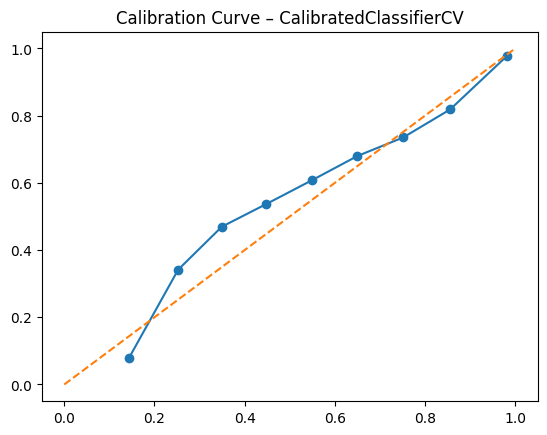

In [20]:
from sklearn.calibration import calibration_curve
prob_true, prob_pred = calibration_curve(y_test['result_name'], yhat_test, n_bins=10)

import matplotlib.pyplot as plt
plt.plot(prob_pred, prob_true, marker='o')
plt.plot([0,1],[0,1],"--")
plt.title("Calibration Curve – CalibratedClassifierCV")
plt.show()

---

## Atomic VAEP + Classificador_sucesso

In [21]:
## Scores
train_score = calib.predict_proba(X_train_enriquecido)[:, 1]
test_score = calib.predict_proba(X_test_enriquecido)[:, 1]
len(train_score)

683785

In [22]:
X_train['success_score'] = train_score
X_test['success_score'] = test_score

In [23]:
print("\n### TREINANDO MODELO VAEP FINAL (com success_score) ###")
final_vaep_models = {}
for target in ['scores', 'concedes']:
    clf = XGBClassifier(
        n_estimators=100,
        max_depth=3,
        enable_categorical=True,
        n_jobs=-3,
        reg_lambda=1.0,
        reg_alpha=0.1
    )
    clf.fit(X_train, y_train[target])
    final_vaep_models[target] = clf
    
    yhat_train = clf.predict_proba(X_train)[:, 1]
    yhat_test = clf.predict_proba(X_test)[:, 1]
    evaluate(y_train[target], yhat_train, label=f"FINAL VAEP {target} - TRAIN")
    evaluate(y_test[target], yhat_test, label=f"FINAL VAEP {target} - TEST")


### TREINANDO MODELO VAEP FINAL (com success_score) ###
### FINAL VAEP SCORES - TRAIN ###
  Brier score : 0.01085 (0.01100)
  Log loss    : 0.05324 (0.00150)
  ROC AUC     : 0.84165

### FINAL VAEP SCORES - TEST ###
  Brier score : 0.01017 (0.01030)
  Log loss    : 0.05142 (0.00144)
  ROC AUC     : 0.81214

### FINAL VAEP CONCEDES - TRAIN ###
  Brier score : 0.00218 (0.00218)
  Log loss    : 0.01284 (0.00036)
  ROC AUC     : 0.88479

### FINAL VAEP CONCEDES - TEST ###
  Brier score : 0.00189 (0.00190)
  Log loss    : 0.01251 (0.00035)
  ROC AUC     : 0.78617



---

## Feature Importance no VAEP


Top 10 features por ganho (total_gain):
                      total_gain
actiontype_goal_a0  73908.890625
success_score       20934.023438
actiontype_shot_a0  13174.971680
x_a0                 4279.876953
dx_a0                1053.505493
y_a0                  773.400330
time_delta_1          767.478760
dist_to_goal_a0       740.059631
time_seconds_a2       727.468506
team_1                585.431030

Importância de success_score: 20934.0234


<Axes: title={'center': 'Top 10 Feature Importances (total_gain)'}>

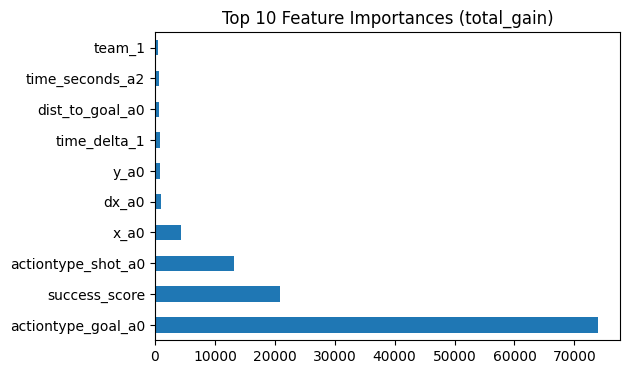

In [32]:
# ─────────── AQUI ───────────
# Calcular feature importance da coluna success_score no modelo 'scores'
scores_model = final_vaep_models['scores']
booster = scores_model.get_booster()
imp_dict = booster.get_score(importance_type='total_gain')

import pandas as pd
imp_df = (
    pd.DataFrame.from_dict(imp_dict, orient='index', columns=['total_gain'])
      .sort_values('total_gain', ascending=False)
)
print("\nTop 10 features por ganho (total_gain):")
print(imp_df.head(10))

if 'success_score' in imp_df.index:
    print(f"\nImportância de success_score: {imp_df.loc['success_score','total_gain']:.4f}")
else:
    print("\nA coluna 'success_score' não apareceu entre as features usadas (verifique se ela está em X_train).")

# Se quiser visualizar graficamente:
imp_df.head(10).plot.barh(figsize=(6,4), legend=False, title="Top 10 Feature Importances (total_gain)")

---

## Predições - Jogadores

In [25]:
# ==========================
# 6. PREDIÇÕES
# ==========================

def generate_predictions(features, models):
    if 'success_score' not in features.columns:
        features_enriquecido = enrich_features(features, features.index.isin(features.index)) # Enriquece todo o conjunto
        success_score_all = models['result_name'].predict_proba(features_enriquecido)[:, 1]
        features['success_score'] = success_score_all
        
    preds = {}
    for m in ['scores', 'concedes']:
        preds[m] = models[m].predict_proba(features)[:, 1]
    return pd.DataFrame(preds)

preds_my = generate_predictions(features, {'result_name': classificador_sucesso, **final_vaep_models})


In [26]:
def calculate_action_values(spadl, predictions):
    values = fm.value(actions=spadl, Pscores=predictions['scores'], Pconcedes=predictions['concedes'])
    return pd.concat([
        spadl[['game_id', 'action_id', 'player_id', 'type_name']],
        predictions.rename(columns={'scores': 'Pscores', 'concedes': 'Pconcedes'}),
        values
    ], axis=1)

vaep_my = calculate_action_values(df_atomic, preds_my)


In [27]:
print(vaep_my.sort_values('vaep_value', ascending=False).head())

vaep_by_player = vaep_my.groupby('player_id')['vaep_value'].sum().sort_values(ascending=False)
print("\nVAEP total por jogador:")
print(vaep_by_player.head())

        game_id  action_id player_id type_name  Pscores  Pconcedes  \
727856    13659     727856     18898      goal      1.0   0.008122   
106926    13382     106926      7696      goal      1.0   0.003022   
69193     13365      69193       265      goal      1.0   0.006179   
592138    13599     592138      1900      goal      1.0   0.003261   
804243    13693     804243      4915      goal      1.0   0.001765   

        offensive_value  defensive_value  vaep_value  
727856         0.948877         0.105759    1.054636  
106926         0.959034         0.095263    1.054297  
69193          0.977059         0.044614    1.021673  
592138         0.964483         0.056005    1.020489  
804243         0.985062         0.033018    1.018080  

VAEP total por jogador:
player_id
4687    31.449251
596     27.693560
1900    27.418293
1732    26.477404
312     26.395233
Name: vaep_value, dtype: float32


---

# Diagnóstico Visual dos Modelos Finais

In [28]:
Y_hat_train_final = pd.DataFrame()
Y_hat_test_final = pd.DataFrame()

for target in ['scores', 'concedes']:
    # Usamos os modelos do 'final_vaep_models' para prever nos conjuntos de treino e teste
    # Note que X_train e X_test aqui são os que contêm a coluna 'success_score'
    Y_hat_train_final[target] = final_vaep_models[target].predict_proba(X_train)[:, 1]
    Y_hat_test_final[target] = final_vaep_models[target].predict_proba(X_test)[:, 1]

print("Predições dos modelos finais coletadas.")

Predições dos modelos finais coletadas.


In [29]:
# %%
# --- ETAPA 9.2: Definição da Função de Plotagem ---
# (Esta é a sua função, copiada aqui para manter a célula autocontida)

def plot_model_diagnostics(y_train, y_test, yhat_train, yhat_test, label):
    """
    Plota curva de calibração, curva ROC e distribuição de probabilidades previstas.
    """
    plt.figure(figsize=(18, 5))

    # -------- Curva de Calibração --------
    plt.subplot(1, 3, 1)
    prob_true_train, prob_pred_train = calibration_curve(y_train, yhat_train, n_bins=10, strategy='uniform')
    prob_true_test, prob_pred_test = calibration_curve(y_test, yhat_test, n_bins=10, strategy='uniform')

    plt.plot(prob_pred_train, prob_true_train, marker='o', label='Treino')
    plt.plot(prob_pred_test, prob_true_test, marker='s', label='Teste')
    plt.plot([0, 1], [0, 1], '--', color='gray', label='Ideal')
    plt.title(f'Curva de Calibração - {label}')
    plt.xlabel('Probabilidade Prevista')
    plt.ylabel('Frequência Real')
    plt.legend()
    plt.grid(True)

    # -------- Curva ROC --------
    plt.subplot(1, 3, 2)
    fpr_train, tpr_train, _ = roc_curve(y_train, yhat_train)
    fpr_test, tpr_test, _ = roc_curve(y_test, yhat_test)

    auc_train = roc_auc_score(y_train, yhat_train)
    auc_test = roc_auc_score(y_test, yhat_test)

    plt.plot(fpr_train, tpr_train, label=f'Treino (AUC={auc_train:.5f})')
    plt.plot(fpr_test, tpr_test, label=f'Teste (AUC={auc_test:.5f})')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.title(f'Curva ROC - {label}')
    plt.xlabel('Taxa de Falsos Positivos (FPR)')
    plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
    plt.legend()
    plt.grid(True)

    # -------- Distribuição das Probabilidades Previstas --------
    plt.subplot(1, 3, 3)
    sns.kdeplot(yhat_train, label='Treino', fill=True)
    sns.kdeplot(yhat_test, label='Teste', fill=True)
    plt.title(f'Distribuição de Probabilidades - {label}')
    plt.xlabel('Probabilidade prevista')
    plt.ylabel('Densidade')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()


### GRÁFICOS DE DIAGNÓSTICO PARA OS MODELOS VAEP FINAIS ###



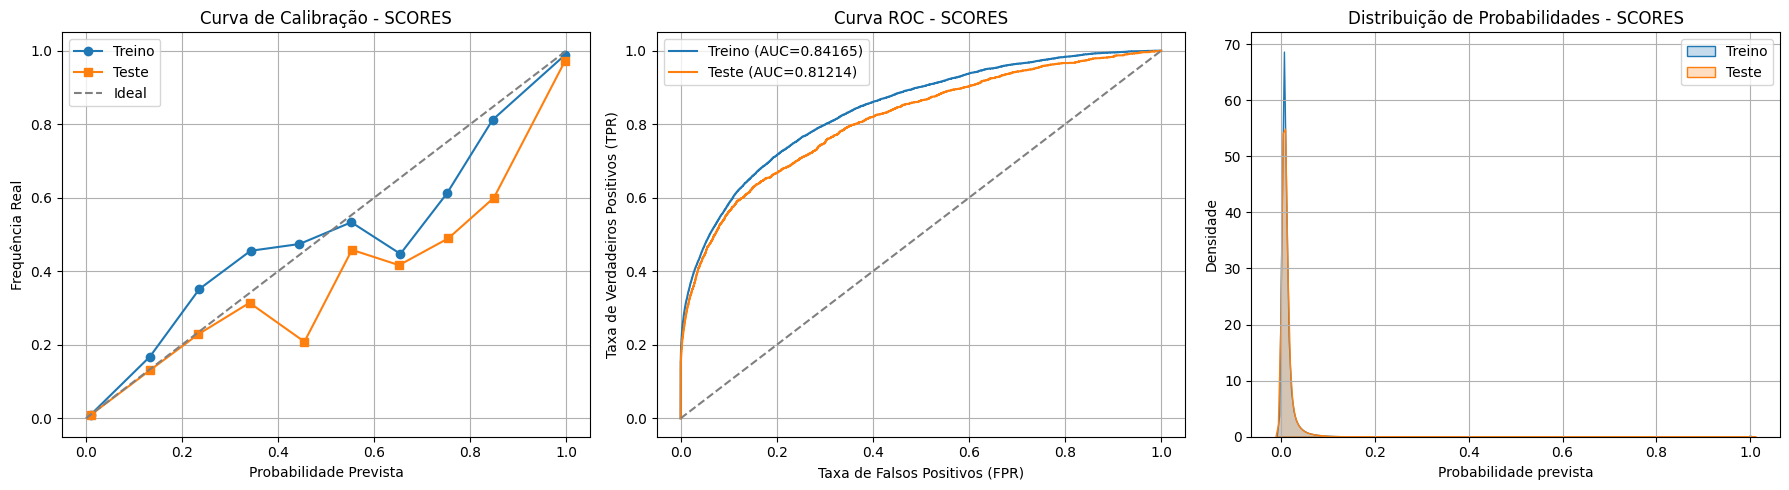

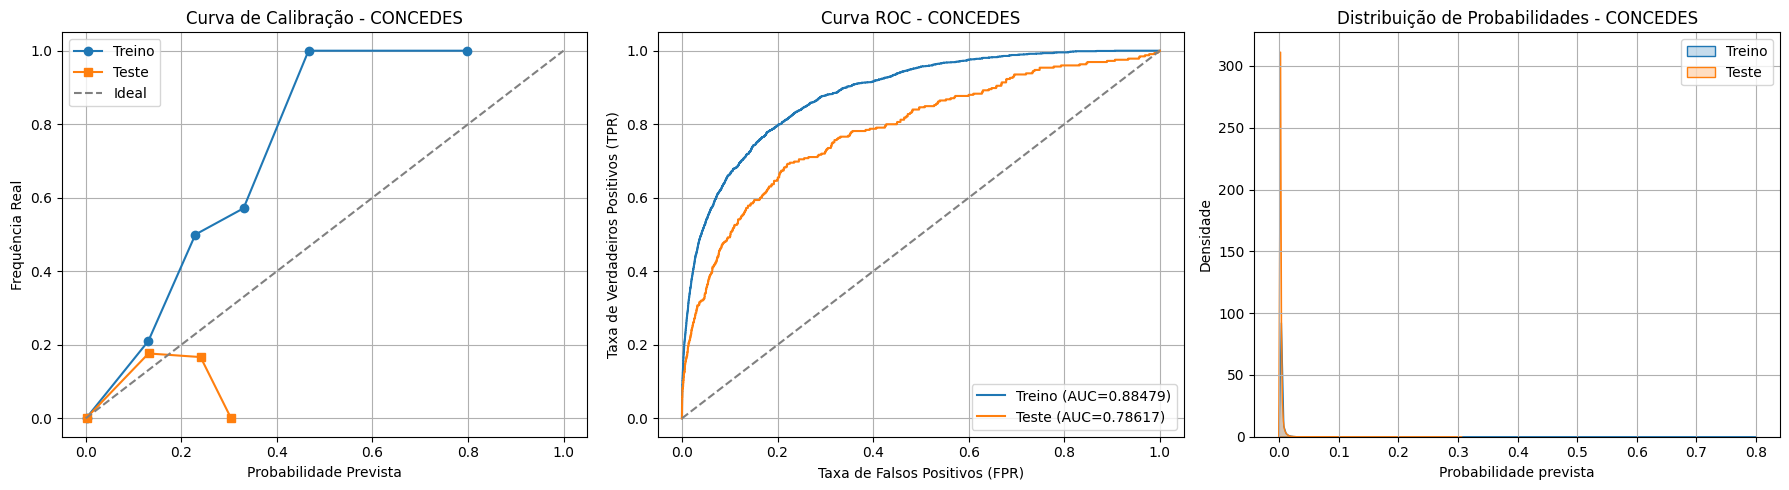

In [30]:
print("\n### GRÁFICOS DE DIAGNÓSTICO PARA OS MODELOS VAEP FINAIS ###\n")

for col in ['scores', 'concedes']:
    plot_model_diagnostics(
        y_train[col], 
        y_test[col], 
        Y_hat_train_final[col], 
        Y_hat_test_final[col], 
        label=col.upper()
    )